# Latest model vs. naive: point-in-time comparison (2008-2026)

Compare only the baseline `NaivePairsTradingModel` and the latest tested V7 configuration (VIX floor 12), using the same year-specific point-in-time pair selections for 2008-2026. Metrics are calculated from equal-weighted daily portfolio returns, before costs for gross and after 5 bp transaction costs plus 50 bp annual borrow for net.

V7 includes its 8% volatility-targeted dynamic leverage (capped at 4x); the naive baseline is unlevered. This compares the implemented strategies, not leverage-matched signals. 2026 is partial through the last available backtest date. The sample, including 2018 onward, has been examined during model development.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

PERIOD_START = 2008
PERIOD_END = 2026
RESULTS_DIR = Path("backtest_results")
NAIVE_DIR = RESULTS_DIR / "latest_vs_naive_2008_2026"
V7_BACKTEST_DIR = RESULTS_DIR / "v7_vix_floor_12_2008_2017"
V7_HOLDOUT_DIR = RESULTS_DIR / "v7_vix_floor_12_2018_2026"
MODEL_FILES = {
    "Gross": {
        "Naive": [NAIVE_DIR / "naive_daily_results_gross.csv"],
        "V7 (VIX floor 12)": [
            V7_BACKTEST_DIR / "daily_results_gross.csv",
            V7_HOLDOUT_DIR / "daily_results_gross.csv",
        ],
    },
    "Net (5 bp + 50 bp borrow)": {
        "Naive": [NAIVE_DIR / "naive_daily_results_net.csv"],
        "V7 (VIX floor 12)": [
            V7_BACKTEST_DIR / "daily_results_net_5bps_borrow_50.csv",
            V7_HOLDOUT_DIR / "daily_results_net_5bps_borrow_50.csv",
        ],
    },
}


def load_model_daily(paths, model_name):
    frames = []
    for path in paths:
        if not path.exists():
            raise FileNotFoundError(f"Missing {path}.")
        frame = pd.read_csv(path, parse_dates=["date"], low_memory=False)
        frame = frame.loc[
            frame["model_name"].eq(model_name)
            & frame["date"].dt.year.between(PERIOD_START, PERIOD_END)
        ].copy()
        if frame.empty:
            raise ValueError(f"No {model_name} rows in {path}.")
        frames.append(frame)
    return pd.concat(frames, ignore_index=True)


def portfolio_metrics(daily):
    returns = daily.groupby("date")["strategy_return"].mean().sort_index()
    wealth = (1 + returns).cumprod()
    volatility = returns.std(ddof=1)
    return {
        "observations": len(returns),
        "total_return": wealth.iloc[-1] - 1,
        "annualized_return": wealth.iloc[-1] ** (252 / len(returns)) - 1,
        "annualized_volatility": volatility * np.sqrt(252),
        "sharpe_ratio": returns.mean() / volatility * np.sqrt(252) if volatility > 0 else np.nan,
        "max_drawdown": (wealth / wealth.cummax().clip(lower=1) - 1).min(),
        "average_pair_gross_exposure": daily["position_gross_exposure"].mean(),
        "average_daily_turnover": daily["turnover"].mean(),
    }, returns


daily_by_scenario = {}
portfolio_rows = []
yearly_rows = []
for cost_scenario, models in MODEL_FILES.items():
    daily_by_scenario[cost_scenario] = {}
    for model_name, (path_list) in models.items():
        source_name = "naive_base" if model_name == "Naive" else "v7_vix_floor"
        daily = load_model_daily(path_list, source_name)
        daily_by_scenario[cost_scenario][model_name] = daily
        metrics, returns = portfolio_metrics(daily)
        portfolio_rows.append({"cost_scenario": cost_scenario, "model": model_name, **metrics})
        for year, year_returns in returns.groupby(returns.index.year):
            annual_volatility = year_returns.std(ddof=1)
            yearly_rows.append({
                "cost_scenario": cost_scenario,
                "year": year,
                "model": model_name,
                "total_return": (1 + year_returns).prod() - 1,
                "sharpe_ratio": (
                    year_returns.mean() / annual_volatility * np.sqrt(252)
                    if annual_volatility > 0 else np.nan
                ),
            })

for cost_scenario, models in daily_by_scenario.items():
    naive_dates = set(models["Naive"]["date"].unique())
    v7_dates = set(models["V7 (VIX floor 12)"]["date"].unique())
    if naive_dates != v7_dates:
        raise ValueError(f"Naive and V7 dates differ for {cost_scenario}.")
    naive_pairs = models["Naive"].groupby(models["Naive"]["date"].dt.year)["pair_id"].apply(set)
    v7_pairs = models["V7 (VIX floor 12)"].groupby(
        models["V7 (VIX floor 12)"]["date"].dt.year
    )["pair_id"].apply(set)
    if not naive_pairs.equals(v7_pairs):
        raise ValueError(f"Naive and V7 pair selections differ for {cost_scenario}.")

portfolio_comparison = pd.DataFrame(portfolio_rows).set_index(["cost_scenario", "model"])
yearly_comparison = pd.DataFrame(yearly_rows).pivot(
    index=["cost_scenario", "year"],
    columns="model",
    values=["total_return", "sharpe_ratio"],
)

print(f"Equal-weight portfolio comparison: {PERIOD_START}-{PERIOD_END}")
display(portfolio_comparison.round(4))
print("Annual portfolio returns and Sharpe ratios")
display(yearly_comparison.round(3))

Equal-weight portfolio comparison: 2008-2026


observations  total_return  \
cost_scenario             model                                           
Gross                     Naive                      4753        0.4768   
                          V7 (VIX floor 12)          4753        1.4792   
Net (5 bp + 50 bp borrow) Naive                      4753        0.2417   
                          V7 (VIX floor 12)          4753        0.6276   

                                             annualized_return  \
cost_scenario             model                                  
Gross                     Naive                         0.0209   
                          V7 (VIX floor 12)             0.0493   
Net (5 bp + 50 bp borrow) Naive                         0.0115   
                          V7 (VIX floor 12)             0.0262   

                                             annualized_volatility  \
cost_scenario             model                                      
Gross                     Naive                             0.0405   
                          V7 (VIX floor 12)                 0.0745   
Net (5 bp + 50 bp borrow) Naive                             0.0404   
                          V7 (VIX floor 12)                 0.0746   

                                             sharpe_ratio  max_drawdown  \
cost_scenario             model                                           
Gross                     Naive                    0.5308       -0.0671   
                          V7 (VIX floor 12)        0.6836       -0.1293   
Net (5 bp + 50 bp borrow) Naive                    0.3041       -0.0798   
                          V7 (VIX floor 12)        0.3834       -0.2011   

                                             average_pair_gross_exposure  \
cost_scenario             model                                            
Gross                     Naive                                   0.6055   
                          V7 (VIX floor 12)                       1.1639   
Net (5 bp + 50 bp borrow) Naive                                   0.6055   
                          V7 (VIX floor 12)                       1.1762   

                                             average_daily_turnover  
cost_scenario             model                                      
Gross                     Naive                              0.0589  
                          V7 (VIX floor 12)                  0.1347  
Net (5 bp + 50 bp borrow) Naive                              0.0589  
                          V7 (VIX floor 12)                  0.1365

Annual portfolio returns and Sharpe ratios


total_return                   sharpe_ratio  \
model                                 Naive V7 (VIX floor 12)        Naive   
cost_scenario             year                                               
Gross                     2008        0.124             0.115        1.769   
                          2009        0.021             0.029        0.542   
                          2010        0.045             0.057        1.678   
                          2011        0.003             0.057        0.073   
                          2012       -0.005             0.012       -0.146   
                          2013        0.009             0.048        0.351   
                          2014        0.006             0.050        0.349   
                          2015        0.014             0.075        0.712   
                          2016       -0.008             0.015       -0.242   
                          2017       -0.004            -0.035       -0.230   
                          2018        0.034             0.044        1.035   
                          2019        0.005             0.069        0.245   
                          2020        0.037             0.067        0.450   
                          2021       -0.001             0.024       -0.024   
                          2022        0.058             0.238        2.868   
                          2023        0.028             0.065        1.115   
                          2024        0.012            -0.019        0.359   
                          2025       -0.014            -0.057       -0.520   
                          2026        0.039             0.106        1.887   
Net (5 bp + 50 bp borrow) 2008        0.105             0.087        1.535   
                          2009        0.011             0.019        0.295   
                          2010        0.039             0.051        1.441   
                          2011       -0.005             0.043       -0.019   
                          2012       -0.012             0.004       -0.352   
                          2013       -0.000             0.029        0.004   
                          2014       -0.003             0.018       -0.140   
                          2015        0.004             0.042        0.196   
                          2016       -0.017            -0.064       -0.550   
                          2017       -0.012            -0.050       -0.718   
                          2018        0.026             0.017        0.787   
                          2019       -0.003             0.049       -0.128   
                          2020        0.027             0.050        0.341   
                          2021       -0.008             0.017       -0.311   
                          2022        0.046             0.199        2.306   
                          2023        0.017             0.046        0.697   
                          2024        0.003            -0.040        0.107   
                          2025       -0.022            -0.077       -0.829   
                          2026        0.028             0.085        1.394   

                                                  
model                          V7 (VIX floor 12)  
cost_scenario             year                    
Gross                     2008             1.135  
                          2009             0.526  
                          2010             0.772  
                          2011             0.580  
                          2012             0.280  
                          2013             0.844  
                          2014             1.009  
                          2015             1.129  
                          2016             0.229  
                          2017            -0.935  
                          2018             0.548  
                          2019             1.033  
                          2020             0.637  
                

## Latest model vs. naive: annual gross Sharpe and VIX

These charts compare the latest tested V7 configuration (VIX floor 12) with the naive baseline. Annual Sharpe uses equal-weighted daily gross portfolio returns; average VIX uses the same dates. The final year is partial. V7's dynamic leverage is included; naive remains unlevered.

,average_vix,Naive Sharpe,V7 (VIX floor 12) Sharpe
year,,,
2008,32.693,1.769,1.135
2009,31.479,0.542,0.526
2010,22.549,1.678,0.772
2011,24.203,0.073,0.580
2012,17.799,-0.146,0.280
2013,14.230,0.351,0.844
2014,14.174,0.349,1.009
2015,16.674,0.712,1.129
2016,15.826,-0.242,0.229


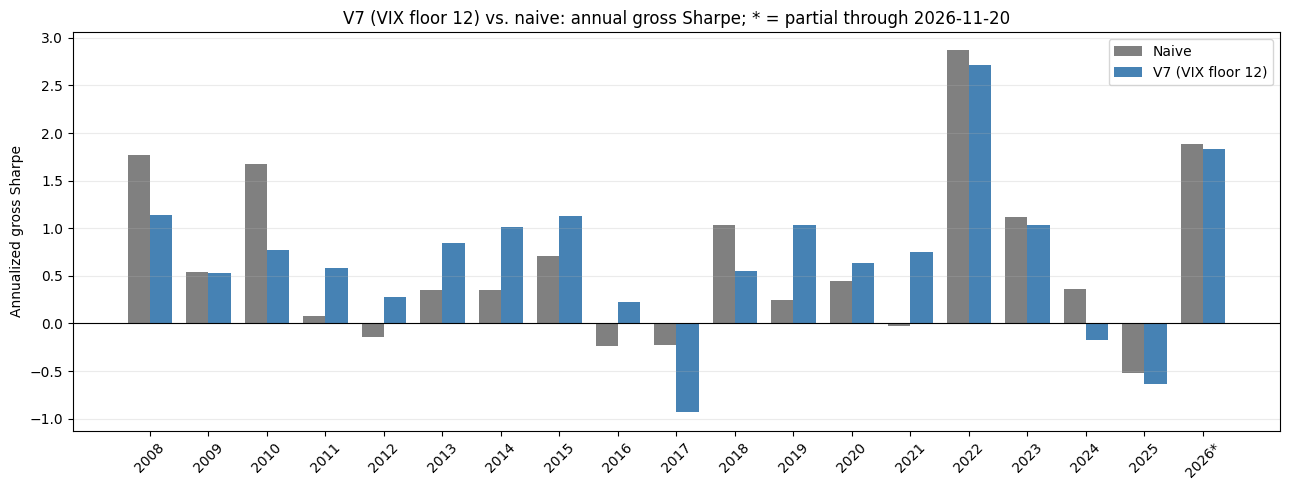

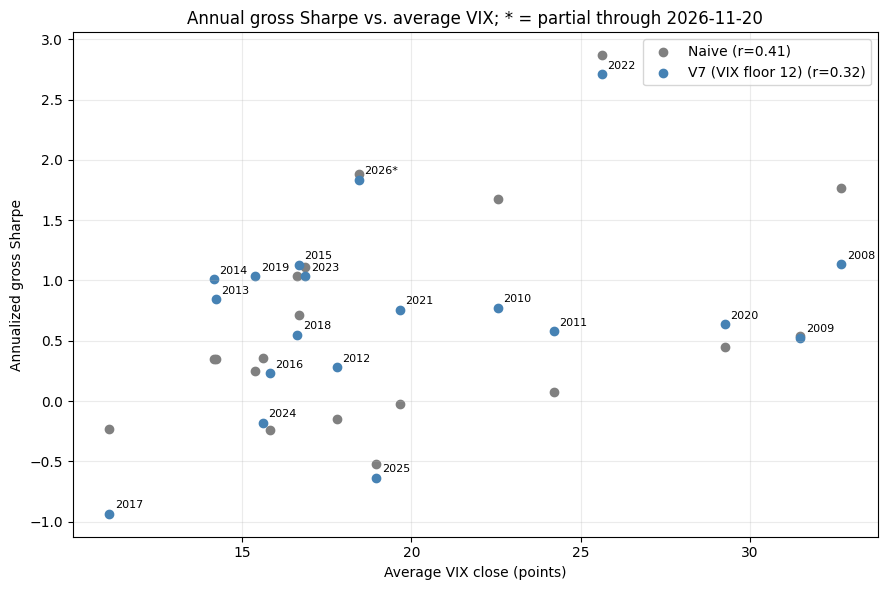

In [2]:
import matplotlib.pyplot as plt

CHART_DIR = RESULTS_DIR / "latest_vs_naive_2008_2026"
CHART_DIR.mkdir(parents=True, exist_ok=True)

vix_close = pd.read_csv(
    Path("data") / "universe_closes.csv",
    usecols=["date", "^VIX"],
    parse_dates=["date"],
).set_index("date")["^VIX"]

gross_returns = {
    model: daily.groupby("date")["strategy_return"].mean().sort_index()
    for model, daily in daily_by_scenario["Gross"].items()
}
all_dates = gross_returns["V7 (VIX floor 12)"].index
annual_stats = pd.DataFrame({"average_vix": vix_close.reindex(all_dates).groupby(all_dates.year).mean()})
if annual_stats["average_vix"].isna().any():
    raise ValueError("VIX closes are missing for some portfolio years.")
for model, returns in gross_returns.items():
    annual_sharpe = returns.groupby(returns.index.year).apply(
        lambda values: values.mean() / values.std(ddof=1) * np.sqrt(252)
        if values.std(ddof=1) > 0 else np.nan
    )
    annual_stats[f"{model} Sharpe"] = annual_sharpe
annual_stats.index.name = "year"
display(annual_stats.round(3))

last_date = max(returns.index.max() for returns in gross_returns.values())
last_year = int(annual_stats.index.max())
partial_note = f"; * = partial through {last_date:%Y-%m-%d}" if last_date.month < 12 else ""
year_labels = [
    f"{year}{'*' if year == last_year and last_date.month < 12 else ''}"
    for year in annual_stats.index
]

fig, ax = plt.subplots(figsize=(13, 5))
years = np.arange(len(annual_stats))
width = 0.38
ax.bar(years - width / 2, annual_stats["Naive Sharpe"], width, label="Naive", color="gray")
ax.bar(
    years + width / 2,
    annual_stats["V7 (VIX floor 12) Sharpe"],
    width,
    label="V7 (VIX floor 12)",
    color="steelblue",
)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(years, year_labels, rotation=45)
ax.set_ylabel("Annualized gross Sharpe")
ax.set_title(f"V7 (VIX floor 12) vs. naive: annual gross Sharpe{partial_note}")
ax.legend()
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(CHART_DIR / "annual_gross_sharpe.png", dpi=160, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(9, 6))
colors = {"Naive": "gray", "V7 (VIX floor 12)": "steelblue"}
for model in gross_returns:
    column = f"{model} Sharpe"
    correlation = annual_stats["average_vix"].corr(annual_stats[column])
    ax.scatter(
        annual_stats["average_vix"],
        annual_stats[column],
        label=f"{model} (r={correlation:.2f})",
        color=colors[model],
    )
    if model == "V7 (VIX floor 12)":
        for year, row in annual_stats.iterrows():
            suffix = "*" if year == last_year and last_date.month < 12 else ""
            ax.annotate(
                f"{year}{suffix}",
                (row["average_vix"], row[column]),
                xytext=(4, 4),
                textcoords="offset points",
                fontsize=8,
            )
ax.set_xlabel("Average VIX close (points)")
ax.set_ylabel("Annualized gross Sharpe")
ax.set_title(f"Annual gross Sharpe vs. average VIX{partial_note}")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(CHART_DIR / "sharpe_vs_average_vix.png", dpi=160, bbox_inches="tight")
plt.show()

### Annual Sharpe by year

![Annual gross Sharpe: V7 versus naive](backtest_results/latest_vs_naive_2008_2026/annual_gross_sharpe.png)

### Annual Sharpe vs. average VIX

![Annual gross Sharpe versus average VIX: V7 versus naive](backtest_results/latest_vs_naive_2008_2026/sharpe_vs_average_vix.png)